Missing values before cleaning:
 Ticker
MDLZ    0
PEP     0
SPY     0
dtype: int64 

Full sample: 2009-01-02 to 2026-11-18  (4498 days)
Formation:   2009-01-02 to 2019-12-31  (2768 days)
Trading:     2020-01-02 to 2026-11-18  (1730 days)
Ticker             PEP       MDLZ         SPY
Date                                         
2026-11-12  142.259995  66.559998  757.119995
2026-11-13  145.440002  67.540001  754.369995
2026-11-16  146.429993  67.540001  739.950012
2026-11-17  142.020004  66.750000  732.440002
2026-11-18  141.660004  66.699997  730.812378


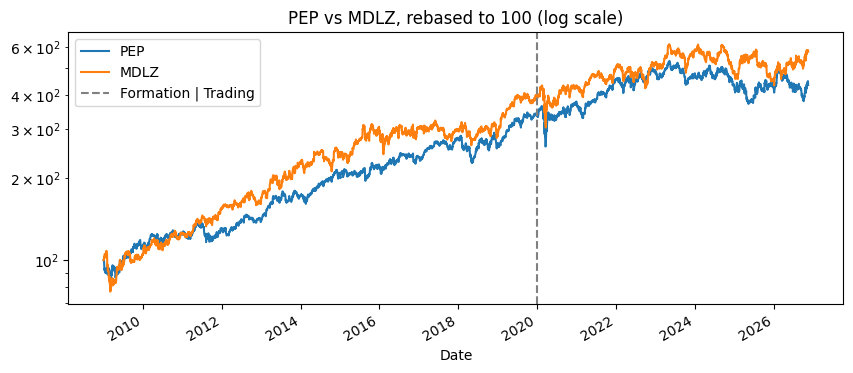

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint

A, B = "PEP", "MDLZ"
MKT = "SPY"
START = "2009-01-01"
FORMATION_END = "2019-12-31"
ENTRY_Z, EXIT_Z = 2.0, 0.0
COST_BP = 5

raw = yf.download([A, B, MKT], start=START, auto_adjust=True, progress=False)["Close"]
print("Missing values before cleaning:\n", raw.isna().sum(), "\n")
px = raw[[A, B, MKT]].dropna()

lp = np.log(px)
rets = lp.diff().dropna()

form = lp.loc[:FORMATION_END]
trade = lp.loc[lp.index > FORMATION_END]

print(f"Full sample: {px.index[0].date()} to {px.index[-1].date()}  ({len(px)} days)")
print(f"Formation:   {form.index[0].date()} to {form.index[-1].date()}  ({len(form)} days)")
print(f"Trading:     {trade.index[0].date()} to {trade.index[-1].date()}  ({len(trade)} days)")
print(px.tail())

ax = (px[[A, B]] / px[[A, B]].iloc[0] * 100).plot(
    logy=True, figsize=(10, 4), title=f"{A} vs {B}, rebased to 100 (log scale)")
ax.axvline(pd.Timestamp(FORMATION_END), color="grey", ls="--", label="Formation | Trading")
ax.legend()
plt.show()

alpha = 1.154, beta = 0.926, R2 = 0.971
EG stat = -3.67, 5% crit = -3.34, p = 0.0201, reverse p = 0.0195
Spread mean = -0.0000, std = 0.0870
Stationary -> trade


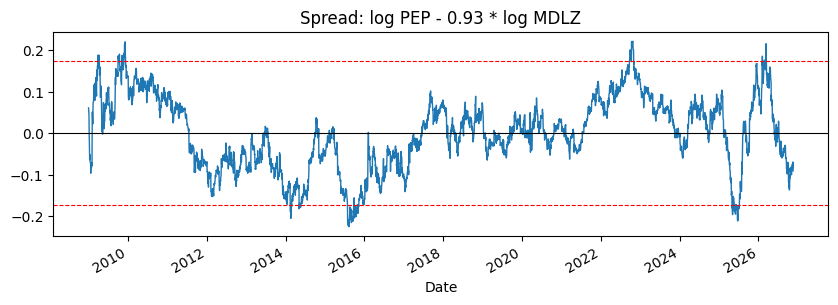

In [7]:
y, x = lp[A], lp[B]
ols = sm.OLS(y, sm.add_constant(x)).fit()
alpha, beta = ols.params
spread = y - alpha - beta * x
mu, sigma = spread.mean(), spread.std()

stat, p, crit = coint(y, x)
p_rev = coint(x, y)[1]

print(f"alpha = {alpha:.3f}, beta = {beta:.3f}, R2 = {ols.rsquared:.3f}")
print(f"EG stat = {stat:.2f}, 5% crit = {crit[1]:.2f}, p = {p:.4f}, reverse p = {p_rev:.4f}")
print(f"Spread mean = {mu:.4f}, std = {sigma:.4f}")
print("Stationary -> trade" if p < 0.05 else "Not stationary -> don't trade")

ax = spread.plot(figsize=(10, 3), lw=1, title=f"Spread: log {A} - {beta:.2f} * log {B}")
ax.axhline(mu, color="black", lw=0.8)
ax.axhline(mu + 2 * sigma, color="red", ls="--", lw=0.8)
ax.axhline(mu - 2 * sigma, color="red", ls="--", lw=0.8)
plt.show()

alpha = 1.154, beta = 0.926, R2 = 0.971
EG stat = -3.67, 5% crit = -3.34, p = 0.0201, reverse p = 0.0195
Spread mean = -0.0000, std = 0.0870
Stationary -> trade


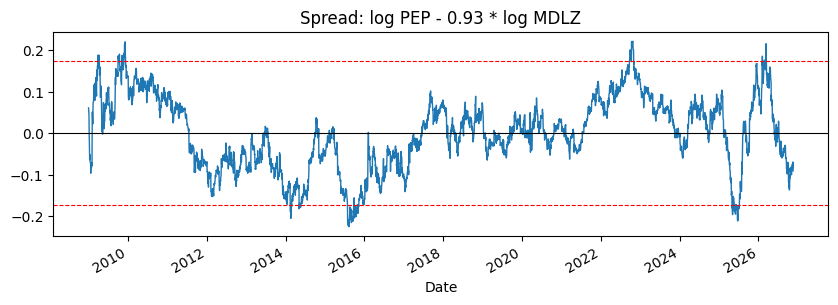

In [9]:
y, x = lp[A], lp[B]
ols = sm.OLS(y, sm.add_constant(x)).fit()
alpha, beta = ols.params
spread = y - alpha - beta * x
mu, sigma = spread.mean(), spread.std()

stat, p, crit = coint(y, x)
p_rev = coint(x, y)[1]

print(f"alpha = {alpha:.3f}, beta = {beta:.3f}, R2 = {ols.rsquared:.3f}")
print(f"EG stat = {stat:.2f}, 5% crit = {crit[1]:.2f}, p = {p:.4f}, reverse p = {p_rev:.4f}")
print(f"Spread mean = {mu:.4f}, std = {sigma:.4f}")
print("Stationary -> trade" if p < 0.05 else "Not stationary -> don't trade")

ax = spread.plot(figsize=(10, 3), lw=1, title=f"Spread: log {A} - {beta:.2f} * log {B}")
ax.axhline(mu, color="black", lw=0.8)
ax.axhline(mu + 2 * sigma, color="red", ls="--", lw=0.8)
ax.axhline(mu - 2 * sigma, color="red", ls="--", lw=0.8)
plt.show()

In [11]:
R = px.pct_change()

z = (spread - mu) / sigma
pos = pd.Series(np.nan, index=z.index)
pos[np.sign(z) != np.sign(z.shift(1))] = 0
pos[z > ENTRY_Z] = -1
pos[z < -ENTRY_Z] = 1
pos = pos.ffill().fillna(0)

held = pos.shift(1).fillna(0)
gross = (held * (R[A] - beta * R[B]) / (1 + beta)).fillna(0)
cost = pos.diff().abs().fillna(0) * COST_BP / 1e4
net = gross - cost


def perf(r, held):
    eq = (1 + r).cumprod()
    entries = (held != 0) & (held != held.shift(1))
    trade_pnl = r.groupby(entries.cumsum().where(held != 0)).sum()
    return {
        "total_return": eq.iloc[-1] - 1,
        "ann_return": eq.iloc[-1] ** (252 / len(r)) - 1,
        "ann_vol": r.std() * np.sqrt(252),
        "sharpe": r.mean() / r.std() * np.sqrt(252),
        "max_drawdown": (eq / eq.cummax() - 1).min(),
        "trades": int(entries.sum()),
        "win_rate": (trade_pnl > 0).mean(),
        "avg_hold_days": (held != 0).sum() / max(entries.sum(), 1),
        "time_in_market": (held != 0).mean(),
    }


stats = pd.DataFrame({"gross": perf(gross, held), "net": perf(net, held)})
print(stats.round(4))



                   gross       net
total_return      1.0024    0.9885
ann_return        0.0397    0.0393
ann_vol           0.0438    0.0437
sharpe            0.9109    0.9028
max_drawdown     -0.0530   -0.0530
trades            7.0000    7.0000
win_rate          1.0000    1.0000
avg_hold_days   172.4286  172.4286
time_in_market    0.2683    0.2683
